In [1]:

import os

print("Available input folders:")

for folder in os.listdir("/kaggle/input"):
    print(folder)


Available input folders:
competitions


In [2]:

import os
import pandas as pd
import numpy as np

# Automatically locate players.csv
INPUT_DIR = "/kaggle/input"
DATA_DIR = None

for root, dirs, files in os.walk(INPUT_DIR):
    if "players.csv" in files:
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "players.csv not found. Please check the attached dataset."
    )

print("Dataset directory:", DATA_DIR)
print("\nCSV files:", os.listdir(DATA_DIR))

# Load small datasets
players = pd.read_csv(os.path.join(DATA_DIR, "players.csv"))
combine_results = pd.read_csv(
    os.path.join(DATA_DIR, "combine_results.csv")
)
career = pd.read_csv(
    os.path.join(DATA_DIR, "player_career_successes.csv")
)

print("\nDataset shapes:")
print("Players:", players.shape)
print("Combine results:", combine_results.shape)
print("Career success:", career.shape)

display(players.head())


Dataset directory: /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027

CSV files: ['players.csv', 'game_tracking_2023.csv', 'game_tracking_2025.csv', 'game_tracking_2024.csv', 'combine_tracking.csv', 'games.csv', 'player_career_successes.csv', 'combine_results.csv', 'player_play.csv']

Dataset shapes:
Players: (510, 10)
Combine results: (510, 18)
Career success: (510, 9)


,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0


In [3]:

# Merge player metadata, Combine results, and career outcomes

master = (
    players
    .merge(
        combine_results,
        on="nfl_id",
        how="left",
        suffixes=("", "_combine")
    )
    .merge(
        career,
        on="nfl_id",
        how="left"
    )
)

print("Master table shape:", master.shape)
print("Unique players:", master["nfl_id"].nunique())

print("\nPositions:")
display(master["nfl_position"].value_counts().to_frame("players"))

print("\nDraft years:")
display(master["draft_year"].value_counts().sort_index().to_frame("players"))

print("\nMissing values in important Combine metrics:")
metrics = [
    "forty",
    "ten_yd_split",
    "three_cone",
    "short_shuttle",
    "vertical",
    "broad_jump",
    "ngs_athleticism_score",
    "ngs_final_score",
]

display(master[metrics].isna().sum().to_frame("missing_values"))


Master table shape: (510, 35)
Unique players: 510

Positions:


,players
nfl_position,
WR,106
CB,60
G,51
T,50
DT,47
TE,42
DE,36
OLB,30
SS,28



Draft years:


,players
draft_year,
2023,160
2024,177
2025,173



Missing values in important Combine metrics:


,missing_values
forty,86
ten_yd_split,85
three_cone,330
short_shuttle,309
vertical,72
broad_jump,87
ngs_athleticism_score,0
ngs_final_score,1


In [4]:

# Load Combine tracking data
combine_tracking = pd.read_csv(
    os.path.join(DATA_DIR, "combine_tracking.csv")
)

print("Tracking shape:", combine_tracking.shape)
print("\nColumns:")
print(combine_tracking.columns.tolist())

# Exclude BALL rows when examining player movements
player_tracking = combine_tracking[
    (combine_tracking["entity_type"] == "PLAYER")
    & (combine_tracking["nfl_id"].notna())
].copy()

print("\nPlayer tracking shape:", player_tracking.shape)

# Understand the available drill categories
drill_summary = (
    player_tracking
    .groupby("drill_type")
    .agg(
        frames=("nfl_id", "size"),
        players=("nfl_id", "nunique"),
        attempts=("event_id", "nunique"),
        drills=("drill_name", "nunique")
    )
    .sort_values("players", ascending=False)
)

display(drill_summary)

# Inspect the most common individual drills
drill_details = (
    player_tracking
    .groupby(["drill_type", "drill_name"])
    .agg(
        frames=("nfl_id", "size"),
        players=("nfl_id", "nunique"),
        attempts=("event_id", "nunique")
    )
    .sort_values("players", ascending=False)
)

display(drill_details.head(25))


Tracking shape: (463189, 14)

Columns:
['draft_year', 'event_id', 'nfl_id', 'entity_type', 'time', 'drill_type', 'drill_name', 'attempt', 'x', 'y', 's', 'a', 'dis', 'dir']

Player tracking shape: (431094, 14)


,frames,players,attempts,drills
drill_type,,,,
FORTY_YARD_DASH,41500,418,793,1
SHORT_SHUTTLE,11690,170,223,1
THREE_CONE_DRILL,15951,160,203,1
SKILL_DRILLS_DB,94623,122,1170,9
SKILL_DRILLS_OL,61129,121,910,8
SKILL_DRILLS_DL,77428,114,1007,11
SKILL_DRILLS_WR,96408,107,1529,15
SKILL_DRILLS_TE,29102,42,438,10
SKILL_DRILLS_LB,3263,4,37,6


frames  \
drill_type       drill_name                                             
FORTY_YARD_DASH  FORTY_YARD_DASH                                41500   
SHORT_SHUTTLE    SHORT_SHUTTLE                                  11690   
THREE_CONE_DRILL THREE_CONE_DRILL                               15951   
SKILL_DRILLS_DB  BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL          8422   
                 BOX_DRILL                                       9439   
                 BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION   21569   
                 W_DRILL                                        10214   
SKILL_DRILLS_OL  FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE         18087   
                 PASS_RUSH_DROP                                 10752   
SKILL_DRILLS_DB  GAUNTLET_DRILL                                 12253   
SKILL_DRILLS_OL  OL_PULL_DRILL_FOLD_BLOCK_RIGHT                  4706   
                 SCREEN_DRILL                                    8031   
SKILL_DRILLS_DL  PASS_RUSH_DRILL                                 9847   
                 FOUR_BAG_AGILITY_DRILL                         11709   
                 FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION    12845   
                 RUN_AND_CLUB_DRILL                              8180   
SKILL_DRILLS_DB  TERYL_AUSTIN_DRILL_2                            9514   
SKILL_DRILLS_DL  BODY_CONTROL_DRILL                              6611   
                 RUN_THE_HOOP_DRILL                              9120   
SKILL_DRILLS_WR  DAGGER_ROUTE_LEFT                               7551   
                 SLANT_ROUTE_LEFT                                4326   
                 GAUNTLET_DRILL                                 18265   
                 CURL_ROUTE_RIGHT                                6210   
SKILL_DRILLS_DB  TERYL_AUSTIN_DRILL_1                            7765   
SKILL_DRILLS_WR  SLOT_STRIKE_ROUTE_LEFT                          6339   

                                                               players  \
drill_type       drill_name                                              
FORTY_YARD_DASH  FORTY_YARD_DASH                                   418   
SHORT_SHUTTLE    SHORT_SHUTTLE                                     170   
THREE_CONE_DRILL THREE_CONE_DRILL                                  160   
SKILL_DRILLS_DB  BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL            122   
                 BOX_DRILL                                         122   
                 BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION      122   
                 W_DRILL                                           121   
SKILL_DRILLS_OL  FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE            120   
                 PASS_RUSH_DROP                                    120   
SKILL_DRILLS_DB  GAUNTLET_DRILL                                    119   
SKILL_DRILLS_OL  OL_PULL_DRILL_FOLD_BLOCK_RIGHT                    119   
                 SCREEN_DRILL                                      119   
SKILL_DRILLS_DL  PASS_RUSH_DRILL                                   114   
                 FOUR_BAG_AGILITY_DRILL                            112   
                 FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION       112   
                 RUN_AND_CLUB_DRILL                                112   
SKILL_DRILLS_DB  TERYL_AUSTIN_DRILL_2                              111   
SKILL_DRILLS_DL  BODY_CONTROL_DRILL                                111   
                 RUN_THE_HOOP_DRILL                                109   
SKILL_DRILLS_WR  DAGGER_ROUTE_LEFT                                 107   
                 SLANT_ROUTE_LEFT                                  107   
                 GAUNTLET_DRILL                                    107   
                 CURL_ROUTE_RIGHT                                  103   
SKILL_DRILLS_DB  TERYL_AUSTIN_DRILL_1                              101   
SKILL_DRILLS_WR  SLOT_STRIKE_ROUTE_LEFT                            101   

                                                               attempts  
drill_type       d

Drill: BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL
Event: 20240301100400_1709337334318_000
Player ID: 57168
Tracking frames: 117


,display_name,nfl_position,draft_year
185,Tyler Nubin,SS,2024


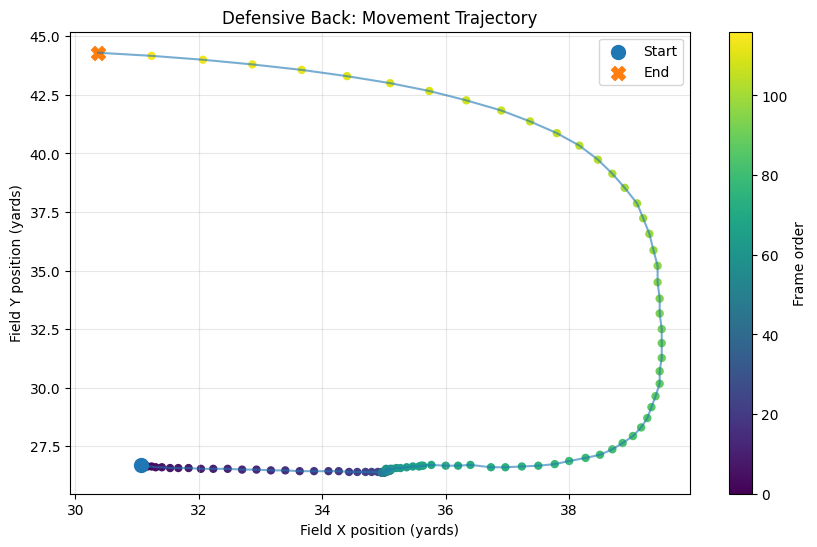

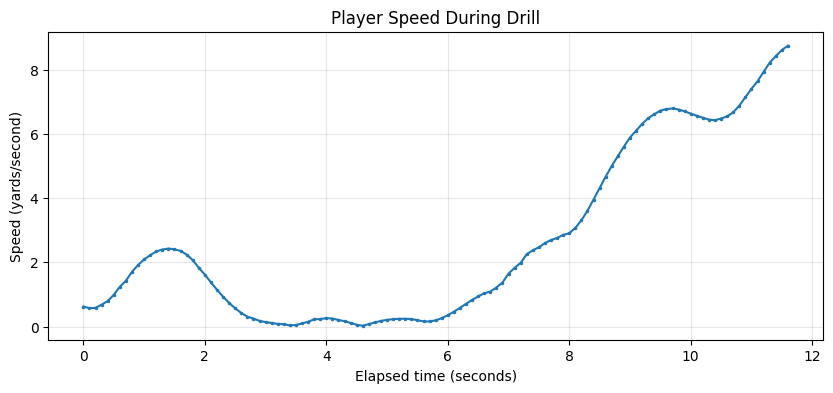

In [5]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Focus on one defensive-back drill
drill_name = "BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL"

db_tracking = player_tracking[
    player_tracking["drill_name"] == drill_name
].copy()

# Find the event with the most tracking frames
event_counts = db_tracking["event_id"].value_counts()
sample_event = event_counts.index[0]

trajectory = db_tracking[
    db_tracking["event_id"] == sample_event
].copy()

trajectory["time"] = pd.to_datetime(trajectory["time"])
trajectory = trajectory.sort_values("time")

player_id = trajectory["nfl_id"].iloc[0]

player_info = master[
    master["nfl_id"] == player_id
][["display_name", "nfl_position", "draft_year"]]

print("Drill:", drill_name)
print("Event:", sample_event)
print("Player ID:", player_id)
print("Tracking frames:", len(trajectory))
display(player_info)

# Plot 1: Movement trajectory
fig, ax = plt.subplots(figsize=(10, 6))

points = ax.scatter(
    trajectory["x"],
    trajectory["y"],
    c=np.arange(len(trajectory)),
    cmap="viridis",
    s=25
)

ax.plot(
    trajectory["x"],
    trajectory["y"],
    alpha=0.6
)

ax.scatter(
    trajectory["x"].iloc[0],
    trajectory["y"].iloc[0],
    marker="o",
    s=100,
    label="Start"
)

ax.scatter(
    trajectory["x"].iloc[-1],
    trajectory["y"].iloc[-1],
    marker="X",
    s=100,
    label="End"
)

ax.set_title("Defensive Back: Movement Trajectory")
ax.set_xlabel("Field X position (yards)")
ax.set_ylabel("Field Y position (yards)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.colorbar(points, ax=ax, label="Frame order")
plt.show()

# Plot 2: Speed over time
elapsed = (
    trajectory["time"] - trajectory["time"].iloc[0]
).dt.total_seconds()

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(elapsed, trajectory["s"], marker=".", markersize=3)
ax.set_title("Player Speed During Drill")
ax.set_xlabel("Elapsed time (seconds)")
ax.set_ylabel("Speed (yards/second)")
ax.grid(True, alpha=0.3)

plt.show()


In [6]:

# Validate the selected attempt
check = trajectory.copy()

check["elapsed_seconds"] = (
    check["time"] - check["time"].iloc[0]
).dt.total_seconds()

print("Frames:", len(check))
print("Unique timestamps:", check["time"].nunique())
print("Duration (seconds):", round(check["elapsed_seconds"].iloc[-1], 2))
print("Duplicate timestamps:", check["time"].duplicated().sum())

print("\nMissing values:")
display(
    check[["x", "y", "s", "a", "dis", "dir"]]
    .isna()
    .sum()
    .to_frame("missing")
)

print("\nMovement statistics:")
display(
    check[["s", "a", "dis"]]
    .describe()
    .round(3)
)

print("\nFirst 5 frames:")
display(
    check[
        ["time", "elapsed_seconds", "x", "y", "s", "a", "dis", "dir"]
    ].head()
)

print("\nLast 5 frames:")
display(
    check[
        ["time", "elapsed_seconds", "x", "y", "s", "a", "dis", "dir"]
    ].tail()
)


Frames: 117
Unique timestamps: 117
Duration (seconds): 11.6
Duplicate timestamps: 0

Missing values:


,missing
x,0
y,0
s,0
a,0
dis,0
dir,0



Movement statistics:


,s,a,dis
count,117.000,117.000,117.000
mean,2.629,2.043,0.130
std,2.695,1.808,0.191
min,0.027,0.045,0.000
25%,0.250,0.548,0.001
50%,1.650,1.526,0.028
75%,5.003,2.996,0.218
max,8.747,6.695,0.751



First 5 frames:


,time,elapsed_seconds,x,y,s,a,dis,dir
234555,2024-03-01 23:55:20.000,0.0,31.066667,26.700000,0.623333,1.029849,0.001571,133.698047
234556,2024-03-01 23:55:20.100,0.1,31.133333,26.666667,0.573333,1.078806,0.004581,124.611142
234557,2024-03-01 23:55:20.200,0.2,31.166667,26.633333,0.583333,1.190565,0.001571,113.498566
234558,2024-03-01 23:55:20.300,0.3,31.233333,26.633333,0.683333,1.390687,0.004444,104.444036
234559,2024-03-01 23:55:20.400,0.4,31.300000,26.600000,0.793333,1.470544,0.004581,98.198069



Last 5 frames:


,time,elapsed_seconds,x,y,s,a,dis,dir
234667,2024-03-01 23:55:31.200,11.2,33.666667,43.566667,7.933333,5.324556,0.542459,288.625299
234668,2024-03-01 23:55:31.300,11.3,32.866667,43.800000,8.220000,4.812097,0.642312,285.191926
234669,2024-03-01 23:55:31.400,11.4,32.066667,44.000000,8.423333,4.287534,0.641249,282.386159
234670,2024-03-01 23:55:31.500,11.5,31.233333,44.166667,8.613333,3.726883,0.695000,279.622692
234671,2024-03-01 23:55:31.600,11.6,30.366667,44.300000,8.746667,3.316052,0.751321,277.357969


In [7]:

# Validate consistency between position, distance, and speed

check = trajectory.copy().sort_values("time").reset_index(drop=True)

dt = check["time"].diff().dt.total_seconds()

# Distance reconstructed from consecutive X/Y positions
dx = check["x"].diff()
dy = check["y"].diff()

check["coordinate_distance"] = np.sqrt(dx**2 + dy**2)

# Expected distance using the previous frame's speed
check["speed_distance"] = check["s"].shift(1) * dt

# Compare against the supplied distance field
valid = check[
    dt.between(0.09, 0.11)
    & check["dis"].notna()
    & check["coordinate_distance"].notna()
].copy()

print("Valid consecutive frame pairs:", len(valid))

print("\nDistance comparison (yards):")
display(
    valid[
        ["coordinate_distance", "dis", "speed_distance"]
    ].describe().round(4)
)

print("\nCorrelation between distance measures:")
display(
    valid[
        ["coordinate_distance", "dis", "speed_distance"]
    ].corr().round(3)
)

# Inspect examples where coordinate distance and supplied distance disagree
valid["distance_difference"] = (
    valid["coordinate_distance"] - valid["dis"]
).abs()

print("\nLargest discrepancies:")
display(
    valid.nlargest(10, "distance_difference")[
        ["time", "x", "y", "s", "dis",
         "coordinate_distance", "speed_distance",
         "distance_difference"]
    ].round(4)
)


Valid consecutive frame pairs: 116

Distance comparison (yards):


,coordinate_distance,dis,speed_distance
count,116.0000,116.0000,116.0000
mean,0.2675,0.1308,0.2576
std,0.2687,0.1915,0.2646
min,0.0000,0.0000,0.0027
25%,0.0333,0.0011,0.0250
50%,0.1683,0.0278,0.1633
75%,0.4869,0.2345,0.4756
max,0.8769,0.7513,0.8613



Correlation between distance measures:


,coordinate_distance,dis,speed_distance
coordinate_distance,1.000,0.960,0.995
dis,0.960,1.000,0.961
speed_distance,0.995,0.961,1.000



Largest discrepancies:


,time,x,y,s,dis,coordinate_distance,speed_distance,distance_difference
107,2024-03-01 23:55:30.700,36.9000,41.8333,6.6733,0.3080,0.6600,0.6547,0.3520
106,2024-03-01 23:55:30.600,37.3667,41.3667,6.5467,0.3127,0.6616,0.6480,0.3490
108,2024-03-01 23:55:30.800,36.3333,42.2667,6.8800,0.3720,0.7134,0.6673,0.3414
105,2024-03-01 23:55:30.500,37.8000,40.8667,6.4800,0.3146,0.6472,0.6427,0.3326
109,2024-03-01 23:55:30.900,35.7333,42.6667,7.1467,0.3940,0.7211,0.6880,0.3272
104,2024-03-01 23:55:30.400,38.1667,40.3333,6.4267,0.3711,0.6708,0.6447,0.2997
110,2024-03-01 23:55:31.000,35.1000,43.0000,7.4033,0.4162,0.7157,0.7147,0.2995
103,2024-03-01 23:55:30.300,38.4667,39.7333,6.4467,0.3641,0.6438,0.6503,0.2797
102,2024-03-01 23:55:30.200,38.7000,39.1333,6.5033,0.3622,0.6325,0.6567,0.2702
111,2024-03-01 23:55:31.100,34.4000,43.3000,7.6433,0.4982,0.7616,0.7403,0.2634


In [8]:

# Compare distance alignment within the selected event

check = trajectory.sort_values("time").copy().reset_index(drop=True)

dx = check["x"].diff()
dy = check["y"].diff()

check["xy_distance"] = np.sqrt(dx**2 + dy**2)

# Test current-frame, previous-frame, and next-frame alignment
check["dis_previous"] = check["dis"].shift(1)
check["dis_next"] = check["dis"].shift(-1)

comparisons = {
    "Current dis": check["dis"],
    "Previous frame dis": check["dis_previous"],
    "Next frame dis": check["dis_next"],
}

results = []

for name, values in comparisons.items():
    pair = pd.DataFrame({
        "xy_distance": check["xy_distance"],
        "candidate_dis": values
    }).dropna()

    results.append({
        "comparison": name,
        "correlation": pair["xy_distance"].corr(
            pair["candidate_dis"]
        ),
        "mean_absolute_error": (
            pair["xy_distance"] - pair["candidate_dis"]
        ).abs().mean(),
        "median_absolute_error": (
            pair["xy_distance"] - pair["candidate_dis"]
        ).abs().median(),
    })

display(pd.DataFrame(results).round(4))

print("\nSample frame-by-frame comparison:")
display(
    check[
        ["time", "x", "y", "xy_distance", "dis", "s"]
    ].iloc[100:116].round(4)
)


,comparison,correlation,mean_absolute_error,median_absolute_error
0,Current dis,0.9599,0.1367,0.1389
1,Previous frame dis,0.9520,0.1435,0.1393
2,Next frame dis,0.9546,0.1306,0.1233



Sample frame-by-frame comparison:


,time,x,y,xy_distance,dis,s
100,2024-03-01 23:55:30.000,39.1000,37.8667,0.6412,0.4012,6.6333
101,2024-03-01 23:55:30.100,38.9000,38.5333,0.6960,0.4462,6.5667
102,2024-03-01 23:55:30.200,38.7000,39.1333,0.6325,0.3622,6.5033
103,2024-03-01 23:55:30.300,38.4667,39.7333,0.6438,0.3641,6.4467
104,2024-03-01 23:55:30.400,38.1667,40.3333,0.6708,0.3711,6.4267
105,2024-03-01 23:55:30.500,37.8000,40.8667,0.6472,0.3146,6.4800
106,2024-03-01 23:55:30.600,37.3667,41.3667,0.6616,0.3127,6.5467
107,2024-03-01 23:55:30.700,36.9000,41.8333,0.6600,0.3080,6.6733
108,2024-03-01 23:55:30.800,36.3333,42.2667,0.7134,0.3720,6.8800
109,2024-03-01 23:55:30.900,35.7333,42.6667,0.7211,0.3940,7.1467


In [9]:

# Validate coordinate distance against recorded distance
# across multiple defensive-back drill attempts.

db = player_tracking[
    (player_tracking["drill_type"] == "SKILL_DRILLS_DB")
    & player_tracking["nfl_id"].notna()
].copy()

db["time"] = pd.to_datetime(db["time"])
db = db.sort_values(["event_id", "time"])

# Coordinate-derived distance between consecutive frames
db["dt"] = db.groupby("event_id")["time"].diff().dt.total_seconds()
db["dx"] = db.groupby("event_id")["x"].diff()
db["dy"] = db.groupby("event_id")["y"].diff()
db["xy_distance"] = np.sqrt(db["dx"]**2 + db["dy"]**2)

# Keep consecutive frames approximately 0.1 seconds apart
valid = db[
    db["dt"].between(0.09, 0.11)
    & db["xy_distance"].notna()
    & db["dis"].notna()
].copy()

# Summarize discrepancies per attempt
attempt_quality = (
    valid.groupby("event_id")
    .agg(
        player_id=("nfl_id", "first"),
        drill_name=("drill_name", "first"),
        frame_pairs=("xy_distance", "size"),
        coordinate_distance_mean=("xy_distance", "mean"),
        recorded_distance_mean=("dis", "mean"),
        distance_mae=("xy_distance",
                      lambda x: np.nan),
    )
    .reset_index()
)

# Calculate MAE separately to keep the aggregation clear
mae = (
    valid.assign(
        abs_error=(valid["xy_distance"] - valid["dis"]).abs()
    )
    .groupby("event_id")["abs_error"]
    .mean()
    .rename("distance_mae")
    .reset_index()
)

attempt_quality = (
    attempt_quality.drop(columns="distance_mae")
    .merge(mae, on="event_id", how="left")
)

print("Valid frame pairs:", len(valid))
print("Attempts evaluated:", len(attempt_quality))

print("\nOverall correlation:")
print(
    valid["xy_distance"].corr(valid["dis"]).round(4)
)

print("\nPer-attempt MAE summary:")
display(attempt_quality["distance_mae"].describe().round(4))

print("\nAttempts with largest discrepancies:")
display(
    attempt_quality.sort_values(
        "distance_mae", ascending=False
    ).head(10)
)





Valid frame pairs: 93453
Attempts evaluated: 1170

Overall correlation:
0.957

Per-attempt MAE summary:


count    1170.0000
mean        0.2172
std         0.0280
min         0.1194
25%         0.2029
50%         0.2175
75%         0.2360
max         0.2801
Name: distance_mae, dtype: float64


Attempts with largest discrepancies:


,event_id,player_id,drill_name,frame_pairs,coordinate_distance_mean,recorded_distance_mean,distance_mae
740,20250228100400_1740783691187_000,58419,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,95,0.596884,0.316793,0.280090
553,20250228100300_1740777238593_000,58382,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,97,0.605837,0.327362,0.278475
749,20250228100400_1740783806765_000,58311,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,102,0.567847,0.289885,0.277962
748,20250228100400_1740783792658_000,58437,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,90,0.603036,0.325134,0.277902
541,20250228100300_1740777113649_000,58232,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,95,0.598033,0.320135,0.277899
1076,640669e0e3d8e72dcdb59ee5-2023,56023,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,65,0.693723,0.416595,0.277128
560,20250228100300_1740777369313_000,58926,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,98,0.619037,0.342434,0.276603
549,20250228100300_1740777197032_000,58293,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,99,0.590573,0.313988,0.276584
735,20250228100400_1740783627444_000,58323,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,98,0.627724,0.351325,0.276399
763,20250228100400_1740784051430_000,58437,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,97,0.623303,0.347247,0.276057


In [10]:

# Compare distance consistency across DB drills

valid = valid.copy()

valid["abs_error"] = (
    valid["xy_distance"] - valid["dis"]
).abs()

valid["signed_error"] = (
    valid["xy_distance"] - valid["dis"]
)

drill_quality = (
    valid.groupby("drill_name")
    .agg(
        frame_pairs=("xy_distance", "size"),
        players=("nfl_id", "nunique"),
        mean_xy_distance=("xy_distance", "mean"),
        mean_recorded_dis=("dis", "mean"),
        mean_absolute_error=("abs_error", "mean"),
        median_absolute_error=("abs_error", "median"),
        mean_signed_error=("signed_error", "mean"),
        correlation=("xy_distance", lambda x: np.nan),
    )
    .reset_index()
)

# Calculate correlation independently for each drill
correlations = (
    valid.groupby("drill_name")
    .apply(
        lambda g: g["xy_distance"].corr(g["dis"]),
        include_groups=False
    )
    .rename("correlation")
    .reset_index()
)

drill_quality = (
    drill_quality.drop(columns="correlation")
    .merge(correlations, on="drill_name", how="left")
    .sort_values("mean_absolute_error", ascending=False)
)

display(drill_quality.round(4))


,drill_name,frame_pairs,players,mean_xy_distance,mean_recorded_dis,mean_absolute_error,median_absolute_error,mean_signed_error,correlation
1,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,21328,122,0.6031,0.3502,0.2529,0.2499,0.2529,0.9691
6,TERYL_AUSTIN_DRILL_1,7662,101,0.4765,0.2473,0.2291,0.2400,0.2291,0.9467
2,BOX_DRILL,9314,122,0.3555,0.1269,0.2286,0.2186,0.2286,0.9716
7,TERYL_AUSTIN_DRILL_2,9401,111,0.5048,0.2884,0.2163,0.2278,0.2163,0.9639
0,BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL,8298,122,0.5178,0.3031,0.2147,0.2231,0.2147,0.9626
5,LINE_DRILL,11728,85,0.5575,0.3527,0.2048,0.2222,0.2048,0.9693
8,W_DRILL,10090,121,0.3793,0.1753,0.2040,0.1956,0.2040,0.9581
4,LINE,3502,33,0.5891,0.3889,0.2002,0.2108,0.2002,0.9741
3,GAUNTLET_DRILL,12130,119,0.6039,0.4399,0.1639,0.1628,0.1639,0.9614


In [11]:

# Compare coordinate-derived speed with recorded speed

speed_check = valid[
    valid["dt"].between(0.09, 0.11)
].copy()

speed_check["coordinate_speed"] = (
    speed_check["xy_distance"] / speed_check["dt"]
)

print(
    "Correlation:",
    round(
        speed_check["coordinate_speed"].corr(speed_check["s"]),
        4
    )
)

print("\nAbsolute speed error (yards/second):")
display(
    (
        speed_check["coordinate_speed"] - speed_check["s"]
    ).abs().describe().round(4)
)


Correlation: 0.9982

Absolute speed error (yards/second):


count    93453.0000
mean         0.1193
std          0.1006
min          0.0000
25%          0.0428
50%          0.0950
75%          0.1722
max          2.8444
dtype: float64

In [12]:
# Inspect the largest differences between coordinate-derived and recorded speed
speed_check = valid[valid["dt"].between(0.09, 0.11)].copy()

speed_check["coordinate_speed"] = (
    speed_check["xy_distance"] / speed_check["dt"]
)
speed_check["speed_error"] = (
    speed_check["coordinate_speed"] - speed_check["s"]
)
speed_check["abs_speed_error"] = speed_check["speed_error"].abs()

# Show the 15 largest discrepancies
columns = [
    "event_id", "nfl_id", "drill_name", "time",
    "dt", "xy_distance", "coordinate_speed", "s",
    "speed_error", "abs_speed_error"
]

display(
    speed_check.nlargest(15, "abs_speed_error")[columns]
    .round(4)
)

# Check the overall error distribution
print("Percentage with absolute error > 0.5 yd/s:",
      round((speed_check["abs_speed_error"] > 0.5).mean() * 100, 3), "%")

print("Percentage with absolute error > 1.0 yd/s:",
      round((speed_check["abs_speed_error"] > 1.0).mean() * 100, 3), "%")

,event_id,nfl_id,drill_name,time,dt,xy_distance,coordinate_speed,s,speed_error,abs_speed_error
182442,20240301100300_1709328704375_000,57347,W_DRILL,2024-03-01 21:31:37.900,0.1,0.5011,5.0111,2.1667,2.8444,2.8444
235631,20240301100400_1709336668660_000,57210,W_DRILL,2024-03-01 23:44:17.800,0.1,0.3480,3.4801,1.8633,1.6168,1.6168
234696,20240301100400_1709336595956_000,57168,W_DRILL,2024-03-01 23:43:09.700,0.1,0.2603,2.6034,1.0133,1.5901,1.5901
282074,20240301100300_1709330552341_000,57339,BOX_DRILL,2024-03-01 22:02:10.400,0.1,0.2687,2.6874,1.1667,1.5208,1.5208
282079,20240301100300_1709330552341_000,57339,BOX_DRILL,2024-03-01 22:02:10.900,0.1,0.4028,4.0277,2.5233,1.5043,1.5043
235632,20240301100400_1709336668660_000,57210,W_DRILL,2024-03-01 23:44:17.900,0.1,0.3682,3.6818,2.2400,1.4418,1.4418
282228,20240301100300_1709329558369_000,57339,TERYL_AUSTIN_DRILL_1,2024-03-01 21:45:49.000,0.1,0.2357,2.3570,0.9400,1.4170,1.4170
213998,20240301100400_1709338099168_000,57225,BOX_DRILL,2024-03-02 00:08:09.900,0.1,0.3283,3.2830,1.8833,1.3996,1.3996
288031,20240301100300_1709328900326_000,57171,W_DRILL,2024-03-01 21:34:54.200,0.1,0.2848,2.8480,1.4633,1.3847,1.3847
147898,20250228100400_1740784302720_000,58311,W_DRILL,2025-02-28 23:11:37.400,0.1,0.3326,3.3260,1.9739,1.3521,1.3521


Percentage with absolute error > 0.5 yd/s: 0.373 %
Percentage with absolute error > 1.0 yd/s: 0.033 %


In [13]:

# Identify high-error frames and examine their frequency by drill

speed_check = speed_check.sort_values(["event_id", "time"]).copy()
speed_check["high_error"] = speed_check["abs_speed_error"] > 0.5

print("High-error frame count:", int(speed_check["high_error"].sum()))
print("Total frame pairs:", len(speed_check))
print(
    "High-error percentage:",
    round(speed_check["high_error"].mean() * 100, 3), "%"
)

# Error frequency by drill
drill_errors = (
    speed_check.groupby("drill_name")
    .agg(
        frame_pairs=("high_error", "size"),
        high_error_frames=("high_error", "sum"),
        median_abs_error=("abs_speed_error", "median"),
        p95_abs_error=(
            "abs_speed_error",
            lambda x: x.quantile(0.95)
        ),
    )
    .reset_index()
)

drill_errors["high_error_pct"] = (
    100 * drill_errors["high_error_frames"]
    / drill_errors["frame_pairs"]
)

display(
    drill_errors.sort_values("high_error_pct", ascending=False)
    .round(3)
)


High-error frame count: 349
Total frame pairs: 93453
High-error percentage: 0.373 %


,drill_name,frame_pairs,high_error_frames,median_abs_error,p95_abs_error,high_error_pct
8,W_DRILL,10090,100,0.103,0.330,0.991
2,BOX_DRILL,9314,87,0.113,0.347,0.934
7,TERYL_AUSTIN_DRILL_2,9401,67,0.103,0.347,0.713
6,TERYL_AUSTIN_DRILL_1,7662,37,0.099,0.328,0.483
0,BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL,8298,15,0.090,0.291,0.181
1,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,21328,24,0.094,0.300,0.113
5,LINE_DRILL,11728,10,0.070,0.269,0.085
3,GAUNTLET_DRILL,12130,9,0.090,0.290,0.074
4,LINE,3502,0,0.113,0.299,0.000


In [14]:

# Check whether high speed errors occur consecutively within attempts

speed_check = speed_check.sort_values(["event_id", "time"]).copy()

speed_check["previous_high_error"] = (
    speed_check.groupby("event_id")["high_error"]
    .shift(1)
    .fillna(False)
    .astype(bool)
)

high = speed_check[speed_check["high_error"]].copy()

# An error run starts when the previous frame pair was not also high-error
high["run_start"] = ~high["previous_high_error"]

print("Attempts with at least one high-error frame:",
      high["event_id"].nunique())

print("Consecutive high-error frame pairs:",
      int((high["previous_high_error"]).sum()))

print("\nHigh-error frames by drill and attempt:")
display(
    high.groupby("drill_name")
    .agg(
        affected_attempts=("event_id", "nunique"),
        high_error_frames=("high_error", "size"),
        consecutive_frames=("previous_high_error", "sum"),
    )
    .sort_values("high_error_frames", ascending=False)
    .reset_index()
)


Attempts with at least one high-error frame: 204
Consecutive high-error frame pairs: 28

High-error frames by drill and attempt:


/tmp/ipykernel_16/1595349531.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


,drill_name,affected_attempts,high_error_frames,consecutive_frames
0,W_DRILL,47,100,12
1,BOX_DRILL,40,87,11
2,TERYL_AUSTIN_DRILL_2,45,67,2
3,TERYL_AUSTIN_DRILL_1,29,37,1
4,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,19,24,0
5,BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL,10,15,1
6,LINE_DRILL,6,10,1
7,GAUNTLET_DRILL,8,9,0


In [15]:

import numpy as np
import pandas as pd

# Defensive-back tracking data
db = player_tracking[
    (player_tracking["drill_type"] == "SKILL_DRILLS_DB")
    & player_tracking["nfl_id"].notna()
].copy()

db["time"] = pd.to_datetime(db["time"], errors="coerce")
db = db.sort_values(["event_id", "time"])

# Calculate movement within each attempt
grouped = db.groupby("event_id", sort=False)

db["dt"] = grouped["time"].diff().dt.total_seconds()
db["dx"] = grouped["x"].diff()
db["dy"] = grouped["y"].diff()
db["coordinate_speed"] = (
    np.sqrt(db["dx"] ** 2 + db["dy"] ** 2) / db["dt"]
)

# Retain plausible adjacent frame intervals
valid_db = db[
    db["dt"].between(0.09, 0.11)
    & db["coordinate_speed"].notna()
    & db["s"].notna()
].copy()

# Summarize each attempt before aggregating players
attempt_features = (
    valid_db.groupby(
        ["nfl_id", "event_id", "drill_name"], dropna=False
    )
    .agg(
        mean_recorded_speed=("s", "mean"),
        max_recorded_speed=("s", "max"),
        mean_coordinate_speed=("coordinate_speed", "mean"),
        max_coordinate_speed=("coordinate_speed", "max"),
        mean_acceleration=("a", "mean"),
        max_acceleration=("a", "max"),
        frame_pairs=("coordinate_speed", "size"),
    )
    .reset_index()
)

# Player-level summaries across attempts
db_player_features = (
    attempt_features.groupby("nfl_id")
    .agg(
        db_attempt_count=("event_id", "nunique"),
        db_drill_count=("drill_name", "nunique"),
        mean_attempt_speed=("mean_recorded_speed", "mean"),
        best_attempt_max_speed=("max_recorded_speed", "max"),
        mean_max_speed=("max_recorded_speed", "mean"),
        mean_max_acceleration=("max_acceleration", "mean"),
        total_valid_frame_pairs=("frame_pairs", "sum"),
    )
    .reset_index()
)

print("Attempt-level feature shape:", attempt_features.shape)
print("Player-level feature shape:", db_player_features.shape)
print("Unique players:", db_player_features["nfl_id"].nunique())

display(db_player_features.head(10))


Attempt-level feature shape: (1170, 10)
Player-level feature shape: (122, 8)
Unique players: 122


,nfl_id,db_attempt_count,db_drill_count,mean_attempt_speed,best_attempt_max_speed,mean_max_speed,mean_max_acceleration,total_valid_frame_pairs
0,55888,9,8,5.275606,9.670000,8.295185,6.088108,788
1,55909,10,8,5.452094,9.556667,8.318000,6.185395,818
2,55910,9,8,5.474965,9.793333,8.525926,6.563555,784
3,55912,9,7,5.763156,9.513333,8.571111,6.179031,726
4,55916,9,8,5.458347,9.626667,8.243704,6.597057,792
5,55921,9,8,5.419087,9.213333,8.604444,6.781812,817
6,55931,9,7,5.595076,10.260000,9.040741,6.434726,809
7,55948,9,8,5.584008,9.856667,8.487778,6.998072,768
8,55960,9,7,5.459284,9.096667,8.077037,5.876125,763
9,55970,9,8,5.434657,9.620000,9.025556,6.626075,768


In [16]:

import numpy as np
import pandas as pd

# Defensive-back tracking data
db = player_tracking[
    (player_tracking["drill_type"] == "SKILL_DRILLS_DB")
    & player_tracking["nfl_id"].notna()
].copy()

db["time"] = pd.to_datetime(db["time"], errors="coerce")
db = db.sort_values(["event_id", "time"])

# Calculate movement within each attempt
grouped = db.groupby("event_id", sort=False)

db["dt"] = grouped["time"].diff().dt.total_seconds()
db["dx"] = grouped["x"].diff()
db["dy"] = grouped["y"].diff()
db["coordinate_speed"] = (
    np.sqrt(db["dx"] ** 2 + db["dy"] ** 2) / db["dt"]
)

# Retain plausible adjacent frame intervals
valid_db = db[
    db["dt"].between(0.09, 0.11)
    & db["coordinate_speed"].notna()
    & db["s"].notna()
].copy()

# Summarize each attempt before aggregating players
attempt_features = (
    valid_db.groupby(
        ["nfl_id", "event_id", "drill_name"], dropna=False
    )
    .agg(
        mean_recorded_speed=("s", "mean"),
        max_recorded_speed=("s", "max"),
        mean_coordinate_speed=("coordinate_speed", "mean"),
        max_coordinate_speed=("coordinate_speed", "max"),
        mean_acceleration=("a", "mean"),
        max_acceleration=("a", "max"),
        frame_pairs=("coordinate_speed", "size"),
    )
    .reset_index()
)

# Player-level summaries across attempts
db_player_features = (
    attempt_features.groupby("nfl_id")
    .agg(
        db_attempt_count=("event_id", "nunique"),
        db_drill_count=("drill_name", "nunique"),
        mean_attempt_speed=("mean_recorded_speed", "mean"),
        best_attempt_max_speed=("max_recorded_speed", "max"),
        mean_max_speed=("max_recorded_speed", "mean"),
        mean_max_acceleration=("max_acceleration", "mean"),
        total_valid_frame_pairs=("frame_pairs", "sum"),
    )
    .reset_index()
)

print("Attempt-level feature shape:", attempt_features.shape)
print("Player-level feature shape:", db_player_features.shape)
print("Unique players:", db_player_features["nfl_id"].nunique())

display(db_player_features.head(10))


Attempt-level feature shape: (1170, 10)
Player-level feature shape: (122, 8)
Unique players: 122


,nfl_id,db_attempt_count,db_drill_count,mean_attempt_speed,best_attempt_max_speed,mean_max_speed,mean_max_acceleration,total_valid_frame_pairs
0,55888,9,8,5.275606,9.670000,8.295185,6.088108,788
1,55909,10,8,5.452094,9.556667,8.318000,6.185395,818
2,55910,9,8,5.474965,9.793333,8.525926,6.563555,784
3,55912,9,7,5.763156,9.513333,8.571111,6.179031,726
4,55916,9,8,5.458347,9.626667,8.243704,6.597057,792
5,55921,9,8,5.419087,9.213333,8.604444,6.781812,817
6,55931,9,7,5.595076,10.260000,9.040741,6.434726,809
7,55948,9,8,5.584008,9.856667,8.487778,6.998072,768
8,55960,9,7,5.459284,9.096667,8.077037,5.876125,763
9,55970,9,8,5.434657,9.620000,9.025556,6.626075,768
